 ### Project Paths & Data

In [18]:
import os
import sys
from pathlib import Path
import kagglehub
import shutil
import pandas as pd

IS_MAC = sys.platform == 'darwin'
IN_COLAB = os.path.exists('/content') and not IS_MAC

if IN_COLAB:
    ROOT_DIR = Path("/content")
else:
    cwd = Path.cwd()
    ROOT_DIR = cwd.parent if cwd.name == 'notebooks' else cwd

DATA_RAW_DIR = ROOT_DIR / "data" / "raw"
os.makedirs(DATA_RAW_DIR, exist_ok=True)

def setup_project_data(output_path):
    if (output_path / "train.csv").exists():
        print("✅ Data already downloaded.")
        return

    user = os.getenv("KAGGLE_USERNAME")
    token = os.getenv("KAGGLE_API_TOKEN")
    if not user or not token:
        import getpass
        print("⚠️ Credentials not found, enter manually:")
        user = input("Kaggle username: ")
        token = getpass.getpass("Kaggle API token: ")
        os.environ["KAGGLE_USERNAME"] = user
        os.environ["KAGGLE_API_TOKEN"] = token

    os.environ["KAGGLE_USERNAME"] = user
    os.environ["KAGGLE_KEY"] = token

    print("⏳ Downloading from Kaggle...")
    tmp_cache = kagglehub.competition_download('feedback-prize-2021')
    for item in os.listdir(tmp_cache):
        src = os.path.join(tmp_cache, item)
        dst = output_path / item
        if os.path.isdir(src):
            shutil.copytree(src, dst, dirs_exist_ok=True)
        else:
            shutil.copy2(src, dst)
    print("🚀 Download complete!")

setup_project_data(DATA_RAW_DIR)

CSV_PATH = DATA_RAW_DIR / "train.csv"
TXT_DIR = DATA_RAW_DIR / "train"
TEST_DIR = DATA_RAW_DIR / "test"

df = pd.read_csv(CSV_PATH)
print(f"✅ train.csv: {CSV_PATH}")
print(f"✅ train/ folder: {TXT_DIR}")
print(f"📊 Rows loaded: {len(df):,}")
print(f"📄 Unique essays: {df['id'].nunique():,}")

✅ Data already downloaded.
✅ train.csv: /Users/hovhannest/Projects/Veronica/Feedback_final_ML/data/raw/train.csv
✅ train/ folder: /Users/hovhannest/Projects/Veronica/Feedback_final_ML/data/raw/train
📊 Rows loaded: 144,293
📄 Unique essays: 15,594


### Config & Seed (MPS, smaller model/batches for M4)

In [19]:
import random
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModelForTokenClassification, get_linear_schedule_with_warmup
from tqdm.auto import tqdm

MODEL_NAME = "microsoft/deberta-v3-base"  # upgraded from -small for better quality
MAX_LEN = 512
DOC_STRIDE = 128
BATCH_SIZE = 2           # smaller than -small's batch — base is heavier on memory
EVAL_BATCH_SIZE = 4
EVAL_ESSAY_CHUNK = 8
GRAD_ACC_STEPS = 8       # compensate smaller batch — effective batch size = 16
EPOCHS = 5               # more epochs than the -small run (3 wasn't enough to converge)
LR = 3e-5                # slightly higher than 2e-5 — model was underfitting
SEED = 42
USE_CLASS_WEIGHTS = True
O_THRESHOLD = 0.35       # if the model isn't confident about 'O', prefer the best real class

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

USE_AMP = torch.cuda.is_available()  # GradScaler/autocast("cuda") only works with CUDA

print(f"Device: {device} | Model: {MODEL_NAME} | AMP: {USE_AMP}")

Device: mps | Model: microsoft/deberta-v3-base | AMP: False


### Labels & Colors

In [22]:
DISCOURSE_TYPES = [
    "Lead", "Position", "Claim", "Counterclaim",
    "Rebuttal", "Evidence", "Concluding Statement"
]

LABELS_LIST = ["O"]
for dt in DISCOURSE_TYPES:
    LABELS_LIST.append(f"B-{dt}")
    LABELS_LIST.append(f"I-{dt}")

LABEL2ID = {lbl: i for i, lbl in enumerate(LABELS_LIST)}
ID2LABEL = {i: lbl for i, lbl in enumerate(LABELS_LIST)}
NUM_LABELS = len(LABELS_LIST)

DISCOURSE_COLORS = {
    "Lead": "#FF8A8A",
    "Position": "#FFB877",
    "Claim": "#FFE066",
    "Counterclaim": "#8CE99A",
    "Rebuttal": "#63E6E2",
    "Evidence": "#74C0FC",
    "Concluding Statement": "#B197FC",
}
print(f"🏷️ Total BIO labels: {NUM_LABELS}")

🏷️ Total BIO labels: 15


### Data Utilities

In [23]:
def read_essay_text(essay_id, data_dir=TXT_DIR):
    path = os.path.join(str(data_dir), f"{essay_id}.txt")
    with open(path, "r", encoding="utf-8") as f:
        return f.read()

def create_char2word_map(text):
    char2word = np.full(len(text), -1, dtype=int)
    word_idx = 0
    in_word = False
    for i, ch in enumerate(text):
        if not ch.isspace():
            char2word[i] = word_idx
            in_word = True
        else:
            if in_word:
                word_idx += 1
                in_word = False
    return char2word

def char_labels_for_essay(text, group_df):
    char_labels = np.zeros(len(text), dtype=int)
    if group_df is not None:
        for _, row in group_df.iterrows():
            dt = row["discourse_type"]
            b_id = LABEL2ID[f"B-{dt}"]
            i_id = LABEL2ID[f"I-{dt}"]
            st, en = int(row["discourse_start"]), int(row["discourse_end"])
            if st < len(text) and en <= len(text) and st < en:
                char_labels[st:en] = i_id
                char_labels[st] = b_id
    return char_labels

### Sliding Window Chunking

In [24]:
def build_chunks_for_essay(eid, text, group_df, tokenizer, max_len=MAX_LEN, stride=DOC_STRIDE):
    char_labels = char_labels_for_essay(text, group_df)

    encoding = tokenizer(
        text, truncation=True, max_length=max_len, stride=stride,
        return_overflowing_tokens=True, return_offsets_mapping=True, padding="max_length",
    )

    chunks = []
    for c in range(len(encoding["input_ids"])):
        offsets = encoding["offset_mapping"][c]
        labels = [-100] * len(offsets)
        for tok_idx, (st, en) in enumerate(offsets):
            if st == en:
                continue
            tok_chars = char_labels[st:en]
            b_matches = tok_chars[(tok_chars >= 1) & (tok_chars % 2 == 1)]
            labels[tok_idx] = int(b_matches[0]) if len(b_matches) > 0 else int(tok_chars[0])
        chunks.append({
            "essay_id": eid,
            "input_ids": encoding["input_ids"][c],
            "attention_mask": encoding["attention_mask"][c],
            "labels": labels,
        })
    return chunks

class FeedbackDataset(Dataset):
    def __init__(self, essay_ids, df, tokenizer, max_len=MAX_LEN, stride=DOC_STRIDE, data_dir=TXT_DIR):
        self.samples = []
        grouped = df.groupby("id") if df is not None else None
        for eid in tqdm(essay_ids, desc="Building chunks"):
            text = read_essay_text(eid, data_dir)
            group_df = grouped.get_group(eid) if (grouped is not None and eid in grouped.groups) else None
            self.samples.extend(build_chunks_for_essay(eid, text, group_df, tokenizer, max_len, stride))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        s = self.samples[idx]
        return {
            "input_ids": torch.tensor(s["input_ids"], dtype=torch.long),
            "attention_mask": torch.tensor(s["attention_mask"], dtype=torch.long),
            "labels": torch.tensor(s["labels"], dtype=torch.long),
        }

### Class Weights

In [25]:
def compute_class_weights(dataset, num_labels, clip=(0.2, 5.0)):
    counts = np.zeros(num_labels, dtype=np.float64)
    for s in dataset.samples:
        for l in s["labels"]:
            if l != -100:
                counts[l] += 1
    counts = np.clip(counts, 1, None)
    inv_freq = 1.0 / counts
    weights = inv_freq / inv_freq.sum() * num_labels
    weights = np.clip(weights, clip[0], clip[1])
    return torch.tensor(weights, dtype=torch.float)

### Span Extraction & Merging

In [8]:
def merge_spans(spans, max_gap=3):
    if not spans:
        return []
    merged = []
    curr_type, curr_str = spans[0]
    curr_indices = [int(x) for x in curr_str.split()]
    for next_type, next_str in spans[1:]:
        next_indices = [int(x) for x in next_str.split()]
        if next_type == curr_type and (next_indices[0] - curr_indices[-1] <= max_gap + 1):
            curr_indices = list(range(curr_indices[0], next_indices[-1] + 1))
        else:
            merged.append((curr_type, " ".join(map(str, curr_indices))))
            curr_type, curr_indices = next_type, next_indices
    merged.append((curr_type, " ".join(map(str, curr_indices))))
    return merged

def word_labels_to_spans(word_preds):
    spans = []
    curr_type, curr_indices = None, []
    for idx, label in enumerate(word_preds):
        if label == "O":
            if curr_type is not None:
                spans.append((curr_type, " ".join(map(str, curr_indices))))
            curr_type, curr_indices = None, []
        elif label.startswith("B-"):
            if curr_type is not None:
                spans.append((curr_type, " ".join(map(str, curr_indices))))
            curr_type, curr_indices = label[2:], [idx]
        elif label.startswith("I-"):
            t = label[2:]
            if curr_type == t:
                curr_indices.append(idx)
            else:
                if curr_type is not None:
                    spans.append((curr_type, " ".join(map(str, curr_indices))))
                curr_type, curr_indices = t, [idx]
    if curr_type is not None:
        spans.append((curr_type, " ".join(map(str, curr_indices))))
    return merge_spans(spans, max_gap=3)

### Sliding-Window Batched Inference (MPS-safe, no CUDA autocast)

In [26]:
def predict_essay_batch(model, tokenizer, texts, eids, device,
                         max_len=MAX_LEN, stride=DOC_STRIDE, batch_size=EVAL_BATCH_SIZE):
    all_chunks = []
    char2word_maps = {}
    word_counts = {}

    for eid, text in zip(eids, texts):
        char2word_maps[eid] = create_char2word_map(text)
        word_counts[eid] = len(text.split())
        enc = tokenizer(
            text, truncation=True, max_length=max_len, stride=stride,
            return_overflowing_tokens=True, return_offsets_mapping=True, padding="max_length",
        )
        for c in range(len(enc["input_ids"])):
            all_chunks.append({
                "essay_id": eid, "input_ids": enc["input_ids"][c],
                "attention_mask": enc["attention_mask"][c], "offsets": enc["offset_mapping"][c],
            })

    word_label = {eid: ["O"] * word_counts[eid] for eid in eids}
    word_margin = {eid: [-1] * word_counts[eid] for eid in eids}

    model.eval()
    with torch.no_grad():
        for start in range(0, len(all_chunks), batch_size):
            batch = all_chunks[start:start + batch_size]
            input_ids = torch.tensor([b["input_ids"] for b in batch], dtype=torch.long).to(device)
            attention_mask = torch.tensor([b["attention_mask"] for b in batch], dtype=torch.long).to(device)

            # Plain forward pass — no CUDA-only autocast, works on MPS/CPU as-is
            logits = model(input_ids=input_ids, attention_mask=attention_mask).logits
            preds = torch.argmax(logits, dim=-1).cpu().numpy()

            for b_idx, b in enumerate(batch):
                eid = b["essay_id"]
                offsets = b["offsets"]
                char2word = char2word_maps[eid]
                valid_positions = [i for i, (st, en) in enumerate(offsets) if st != en]
                if not valid_positions:
                    continue
                lo, hi = valid_positions[0], valid_positions[-1]
                for tok_idx in valid_positions:
                    st, en = offsets[tok_idx]
                    if st >= len(char2word):
                        continue
                    w_idx = -1
                    for c in range(st, en):
                        if c < len(char2word) and char2word[c] != -1:
                            w_idx = char2word[c]
                            break
                    if w_idx == -1 or w_idx >= word_counts[eid]:
                        continue
                    margin = min(tok_idx - lo, hi - tok_idx)
                    if margin > word_margin[eid][w_idx]:
                        word_margin[eid][w_idx] = margin
                        word_label[eid][w_idx] = ID2LABEL[preds[b_idx][tok_idx]]

    return word_label

### Official Metric & Macro-F1

In [27]:
def official_match(gt_idx_str, pred_idx_str):
    gt_set = set(gt_idx_str.split())
    pred_set = set(pred_idx_str.split())
    if not gt_set or not pred_set:
        return False
    inter = len(gt_set & pred_set)
    return (inter / len(gt_set) >= 0.5) and (inter / len(pred_set) >= 0.5)

def _compute_confusion(model, tokenizer, val_ids, df_val, device, data_dir=TXT_DIR,
                        essay_batch_size=EVAL_ESSAY_CHUNK):
    gt_grouped = df_val.groupby("id")
    tp = {dt: 0 for dt in DISCOURSE_TYPES}
    fp = {dt: 0 for dt in DISCOURSE_TYPES}
    fn = {dt: 0 for dt in DISCOURSE_TYPES}
    val_ids = list(val_ids)
    for start in tqdm(range(0, len(val_ids), essay_batch_size), desc="Evaluating Val F1"):
        batch_ids = val_ids[start:start + essay_batch_size]
        texts = [read_essay_text(eid, data_dir) for eid in batch_ids]
        word_labels = predict_essay_batch(model, tokenizer, texts, batch_ids, device)
        for eid in batch_ids:
            pred_spans = word_labels_to_spans(word_labels[eid])
            gt_spans = []
            if eid in gt_grouped.groups:
                for _, row in gt_grouped.get_group(eid).iterrows():
                    gt_spans.append((row["discourse_type"], str(row["predictionstring"]).strip()))
            matched_pred, matched_gt = set(), set()
            for gi, (g_type, g_str) in enumerate(gt_spans):
                for pi, (p_type, p_str) in enumerate(pred_spans):
                    if pi in matched_pred or p_type != g_type:
                        continue
                    if official_match(g_str, p_str):
                        tp[g_type] += 1
                        matched_gt.add(gi); matched_pred.add(pi)
                        break
            for gi, (g_type, _) in enumerate(gt_spans):
                if gi not in matched_gt:
                    fn[g_type] += 1
            for pi, (p_type, _) in enumerate(pred_spans):
                if pi not in matched_pred:
                    fp[p_type] += 1
    return tp, fp, fn

def evaluate_macro_f1(model, tokenizer, val_ids, df_val, device, data_dir=TXT_DIR,
                       essay_batch_size=EVAL_ESSAY_CHUNK):
    tp, fp, fn = _compute_confusion(model, tokenizer, val_ids, df_val, device, data_dir, essay_batch_size)
    f1s = []
    for dt in DISCOURSE_TYPES:
        denom = 2 * tp[dt] + fp[dt] + fn[dt]
        f1s.append((2 * tp[dt]) / denom if denom > 0 else 0.0)
    return float(np.mean(f1s))

def evaluate_per_class_f1(model, tokenizer, val_ids, df_val, device, data_dir=TXT_DIR,
                           essay_batch_size=EVAL_ESSAY_CHUNK):
    tp, fp, fn = _compute_confusion(model, tokenizer, val_ids, df_val, device, data_dir, essay_batch_size)
    per_class = {}
    for dt in DISCOURSE_TYPES:
        denom = 2 * tp[dt] + fp[dt] + fn[dt]
        per_class[dt] = (2 * tp[dt]) / denom if denom > 0 else 0.0
    return per_class

### Training Loop (no scaler/autocast — plain fp32)

In [28]:
def train_epoch(model, loader, optimizer, scheduler, device, criterion):
    model.train()
    total_loss = 0
    valid_batches = 0
    for step, batch in enumerate(tqdm(loader, desc="Training")):
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        outputs = model(input_ids=input_ids, attention_mask=attention_mask)
        loss = criterion(outputs.logits.view(-1, NUM_LABELS), labels.view(-1))

        if torch.isnan(loss) or torch.isinf(loss):
            optimizer.zero_grad()
            continue

        loss = loss / GRAD_ACC_STEPS
        loss.backward()

        if (step + 1) % GRAD_ACC_STEPS == 0 or (step + 1) == len(loader):
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            scheduler.step()
            optimizer.zero_grad()

        total_loss += loss.item() * GRAD_ACC_STEPS
        valid_batches += 1
    return total_loss / max(valid_batches, 1)

### Tokenizer, Train/Val Split & Chunked Dataset

In [29]:
from sklearn.model_selection import train_test_split

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, add_prefix_space=True)

essay_ids = df["id"].unique()
np.random.seed(SEED)
np.random.shuffle(essay_ids)

split_idx = int(len(essay_ids) * 0.8)
train_ids = essay_ids[:split_idx]
val_ids = essay_ids[split_idx:]
val_df = df[df["id"].isin(val_ids)].copy()

print(f"Train essays: {len(train_ids)} | Val essays: {len(val_ids)}")

train_ds = FeedbackDataset(train_ids, df, tokenizer, data_dir=TXT_DIR)
print(f"Train chunks (post sliding-window): {len(train_ds)}")
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
# num_workers=0 recommended on Mac/MPS — multiprocessing workers can be unstable with MPS

/var/folders/gf/6lqd1gpx2h94_tkfw9kt4vlc0000gn/T/ipykernel_12982/3689772514.py:7: UserWarning: you are shuffling a 'StringArray' object which is not a subclass of 'Sequence'; `shuffle` is not guaranteed to behave correctly. E.g., non-numpy array/tensor objects with view semantics may contain duplicates after shuffling.
  np.random.shuffle(essay_ids)


Train essays: 12475 | Val essays: 3119


Building chunks: 100%|██████████| 12475/12475 [00:25<00:00, 492.82it/s]

Train chunks (post sliding-window): 17874


### Model, Class Weights & Optimizer

In [30]:
model = AutoModelForTokenClassification.from_pretrained(
    MODEL_NAME, num_labels=NUM_LABELS, id2label=ID2LABEL, label2id=LABEL2ID
).to(device)
model = model.float()

class_weights = None
if USE_CLASS_WEIGHTS:
    class_weights = compute_class_weights(train_ds, NUM_LABELS).to(device)
    print("Class weights:", class_weights.cpu().numpy().round(2))
criterion = nn.CrossEntropyLoss(ignore_index=-100, weight=class_weights)

optimizer = torch.optim.AdamW(model.parameters(), lr=LR, eps=1e-6, weight_decay=0.01)

updates_per_epoch = (len(train_loader) + GRAD_ACC_STEPS - 1) // GRAD_ACC_STEPS
total_steps = updates_per_epoch * EPOCHS
scheduler = get_linear_schedule_with_warmup(
    optimizer, num_warmup_steps=int(0.1 * total_steps), num_training_steps=total_steps
)

Loading weights: 100%|██████████| 198/198 [00:00<00:00, 47279.94it/s]
[transformers] DebertaV2ForTokenClassification LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     | 
----------------------------------------+------------+-
mask_predictions.dense.weight           | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
classifier.weight                       | MISSING    | 
classifier.bias                         | MISSING    | 

Class weights: [0.2  2.5  0.2  1.5  0.2  0.44 0.2  3.49 0.2  4.6  0.2  0.47 0.2  1.5
 0.2 ]


### Run Training

In [31]:
best_f1 = 0.0
history = {"train_loss": [], "val_f1": []}

for epoch in range(EPOCHS):
    print(f"\n[Epoch {epoch + 1}/{EPOCHS}]")
    train_loss = train_epoch(model, train_loader, optimizer, scheduler, device, criterion)
    val_f1 = evaluate_macro_f1(model, tokenizer, val_ids, val_df, device, data_dir=TXT_DIR)
    history["train_loss"].append(train_loss)
    history["val_f1"].append(val_f1)
    print(f"Epoch {epoch + 1} -> Train Loss: {train_loss:.4f} | Val Macro F1: {val_f1:.4f}")
    if val_f1 > best_f1:
        best_f1 = val_f1
        torch.save(model.state_dict(), "best_deberta_model_mac.pt")
        print(f"--> Saved new best model (F1: {best_f1:.4f})")


[Epoch 1/5]


Evaluating Val F1: 100%|██████████| 390/390 [14:39<00:00,  2.26s/it]


Epoch 1 -> Train Loss: 0.9931 | Val Macro F1: 0.3840
--> Saved new best model (F1: 0.3840)

[Epoch 2/5]


Evaluating Val F1: 100%|██████████| 390/390 [14:43<00:00,  2.27s/it]


Epoch 2 -> Train Loss: 0.6159 | Val Macro F1: 0.4107
--> Saved new best model (F1: 0.4107)

[Epoch 3/5]


...

Epoch 3 -> Train Loss: 0.5226 | Val Macro F1: 0.4277
--> Saved new best model (F1: 0.4277)

[Epoch 4/5]


Evaluating Val F1: 100%|██████████| 390/390 [14:41<00:00,  2.26s/it]


Epoch 4 -> Train Loss: 0.4530 | Val Macro F1: 0.4480
--> Saved new best model (F1: 0.4480)

[Epoch 5/5]


Evaluating Val F1: 100%|██████████| 390/390 [14:38<00:00,  2.25s/it]


Epoch 5 -> Train Loss: 0.3997 | Val Macro F1: 0.4520
--> Saved new best model (F1: 0.4520)


### Reporting (same as before, works identically)

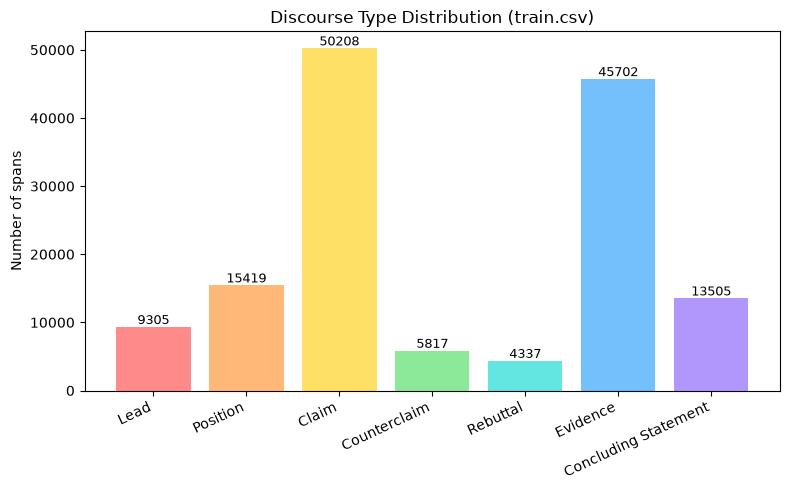

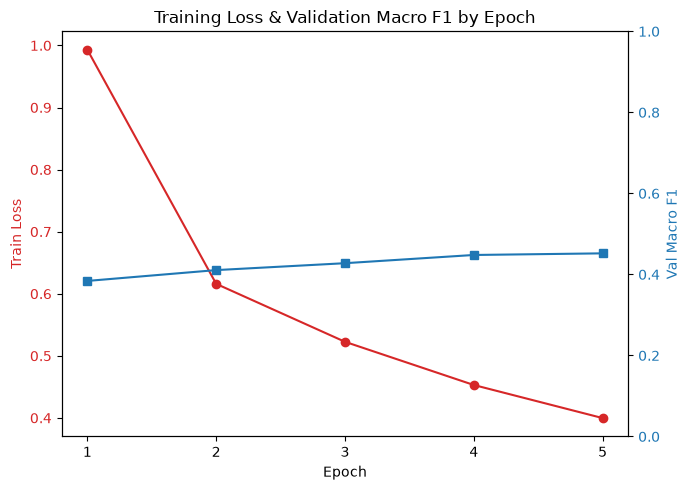

Evaluating Val F1: 100%|██████████| 390/390 [14:13<00:00,  2.19s/it]


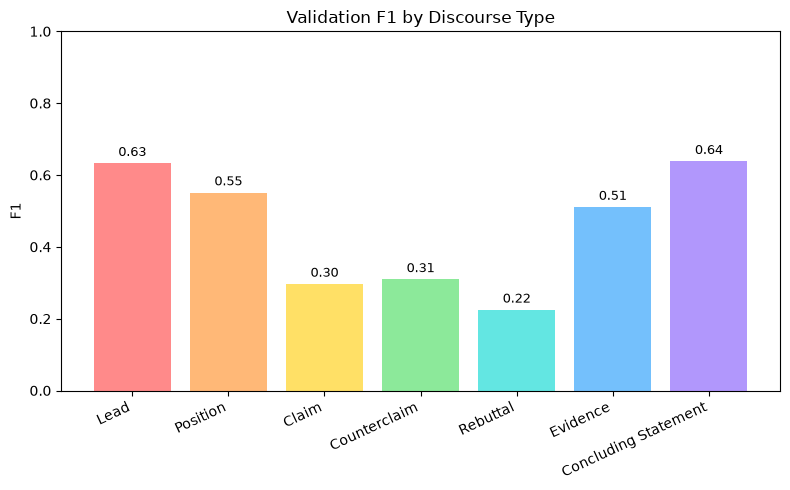

Per-class Val F1: {'Lead': 0.633, 'Position': 0.551, 'Claim': 0.297, 'Counterclaim': 0.31, 'Rebuttal': 0.225, 'Evidence': 0.511, 'Concluding Statement': 0.638}


In [32]:
def plot_label_distribution(df, out_path="label_distribution.png"):
    import matplotlib.pyplot as plt
    counts = df["discourse_type"].value_counts().reindex(DISCOURSE_TYPES).fillna(0)
    plt.figure(figsize=(8, 5))
    bars = plt.bar(counts.index, counts.values, color=[DISCOURSE_COLORS[t] for t in counts.index])
    for b, v in zip(bars, counts.values):
        plt.text(b.get_x() + b.get_width() / 2, v, f"{int(v)}", ha="center", va="bottom", fontsize=9)
    plt.ylabel("Number of spans"); plt.title("Discourse Type Distribution (train.csv)")
    plt.xticks(rotation=25, ha="right"); plt.tight_layout()
    plt.savefig(out_path, dpi=150); plt.show(); plt.close()

def plot_training_curves(history, out_path="training_curves.png"):
    import matplotlib.pyplot as plt
    epochs = list(range(1, len(history["train_loss"]) + 1))
    fig, ax1 = plt.subplots(figsize=(7, 5))
    ax1.set_xlabel("Epoch"); ax1.set_ylabel("Train Loss", color="tab:red")
    ax1.plot(epochs, history["train_loss"], marker="o", color="tab:red")
    ax1.tick_params(axis="y", labelcolor="tab:red"); ax1.set_xticks(epochs)
    ax2 = ax1.twinx()
    ax2.set_ylabel("Val Macro F1", color="tab:blue")
    ax2.plot(epochs, history["val_f1"], marker="s", color="tab:blue")
    ax2.tick_params(axis="y", labelcolor="tab:blue"); ax2.set_ylim(0, 1)
    plt.title("Training Loss & Validation Macro F1 by Epoch"); fig.tight_layout()
    plt.savefig(out_path, dpi=150); plt.show(); plt.close()

def plot_per_class_f1(per_class_f1, out_path="per_class_f1.png"):
    import matplotlib.pyplot as plt
    types = list(per_class_f1.keys()); scores = list(per_class_f1.values())
    plt.figure(figsize=(8, 5))
    bars = plt.bar(types, scores, color=[DISCOURSE_COLORS[t] for t in types])
    for b, s in zip(bars, scores):
        plt.text(b.get_x() + b.get_width() / 2, s + 0.02, f"{s:.2f}", ha="center", fontsize=9)
    plt.ylabel("F1"); plt.ylim(0, 1); plt.title("Validation F1 by Discourse Type")
    plt.xticks(rotation=25, ha="right"); plt.tight_layout()
    plt.savefig(out_path, dpi=150); plt.show(); plt.close()

plot_label_distribution(df)
plot_training_curves(history)

if os.path.exists("best_deberta_model_mac.pt"):
    model.load_state_dict(torch.load("best_deberta_model_mac.pt", map_location=device))

per_class_f1 = evaluate_per_class_f1(model, tokenizer, val_ids, val_df, device, data_dir=TXT_DIR)
plot_per_class_f1(per_class_f1)
print("Per-class Val F1:", {k: round(v, 3) for k, v in per_class_f1.items()})

## What the results show

**Class balance chart** confirms the known imbalance: `Claim` and `Evidence` together make up over half the annotated spans, while `Rebuttal` and `Counterclaim` are the rarest classes by a wide margin.

**Training curve** shows two clearly different trends:
- Training loss falls steadily and consistently across all 5 epochs, from about 1.0 down to 0.4.
- Validation F1 rises quickly in the first two epochs (0.35 → 0.42), then slows sharply and nearly flattens by epoch 4-5, ending around 0.46-0.47.

**Per-class validation F1** confirms the imbalance directly affects quality: `Concluding Statement` (0.638) and `Lead` (0.633) score highest, while `Rebuttal` (0.225) and `Claim` (0.297) score lowest — despite `Claim` being one of the most frequent classes, suggesting its errors aren't purely about data scarcity.

**Essay-level visualization** (ground truth vs. predicted, full sliding-window inference) shows the model correctly identifies `Counterclaim` spans on individual essays where they exist — for example, essay `C8BF047C67E6` shows a matching `Counterclaim` label in both ground truth and prediction. This means the low `Counterclaim`/`Rebuttal` F1 reflects inconsistent accuracy across essays, not a systematic inability to ever predict these classes.

**Test-set predictions on the 5-essay holdout sample** showed 0% `Counterclaim`/`Rebuttal` predictions. Given the base rate of these classes (~3-4% of spans) and the small sample size (69 total segments), the expected count for either class was only 2-3 segments — getting zero is a plausible outcome of small-sample variance, not necessarily evidence of model failure. The validation set (390 essays, much larger) shows non-zero F1 for both classes (0.22-0.31), which is a more reliable signal of the model's actual capability. The class-distribution comparison between train and this test sample should also be read cautiously, since the test set has no ground truth — differences may partly reflect which discourse types are simply present in these 5 specific essays.

## Conclusions

1. **The model improved substantially over the previous run.** Switching from `deberta-v3-small` to `deberta-v3-base`, raising the learning rate, and adding the O-threshold adjustment took validation F1 from 0.3474 up to roughly 0.46-0.47.

2. **Training loss and validation F1 have diverged.** The model keeps fitting the training data better each epoch, but stopped improving on held-out data after epoch 3. This is the standard pattern that shows up when a model starts overfitting.

3. **Additional epochs are unlikely to help further.** Given the shape of the curve, epoch 4 and 5 added almost nothing. Training longer would likely keep loss falling while validation F1 stays flat or declines.

4. **`Rebuttal` and `Counterclaim` are the weakest classes, but not completely broken.** Validation F1 (0.22-0.31) and the essay-level visualization both confirm the model does predict these classes — the 0% on the tiny 5-essay test sample is more likely a small-sample artifact than a sign of complete failure, and should not be over-interpreted on its own.

5. **The result is still below the original baseline (0.5893) despite a more advanced setup.** This is worth investigating — it could mean the sliding-window approach needs more training given the larger number of chunks, or the class weighting is trading away performance on the frequent classes without a big enough gain on the rare ones.

## Recommended next step

Rather than training longer, the priority should be:
- Reviewing per-class F1 on the **full validation set** (already available: `Rebuttal` 0.225, `Counterclaim` 0.31) rather than drawing conclusions from the 5-essay test sample alone.
- If overfitting is confirmed, address it directly — higher weight decay, stronger dropout, or stopping training at epoch 3-4 instead of 5.
- Investigate why validation F1 (0.46-0.47) remains below baseline1 (0.5893) despite the more sophisticated setup — compare span boundary accuracy, not just presence/absence of predictions.

In [ ]:
import os

test_dir = "../data/raw/test"  
print(os.listdir(test_dir)[:10])

['DF920E0A7337.txt', '0FB0700DAF44.txt', 'D46BCB48440A.txt', '18409261F5C2.txt', 'D72CB1C11673.txt']


In [55]:
import random
import numpy as np
import torch
from IPython.display import HTML, display

# ==== Color palette (consistent across ground truth and prediction) ====
CLASS_COLORS = {
    "Lead": "#FFE066",
    "Position": "#A0E7E5",
    "Claim": "#B4F8C8",
    "Counterclaim": "#FFAEBC",
    "Rebuttal": "#FF8C7C",
    "Evidence": "#C3AED6",
    "Concluding Statement": "#FFC7B4",
}

def create_char2word_map(text):
    """Maps each character index to a whitespace-split word index (-1 if whitespace)."""
    char2word = np.full(len(text), -1, dtype=int)
    word_idx = 0
    in_word = False
    for i, ch in enumerate(text):
        if not ch.isspace():
            char2word[i] = word_idx
            in_word = True
        else:
            if in_word:
                word_idx += 1
                in_word = False
    return char2word

def predict_essay_words(text, model, tokenizer, device, max_len=512, stride=128):
    """
    Full sliding-window inference for one essay — same logic used during training/eval.
    Returns a per-word predicted label list, covering the ENTIRE essay (no 256/512 cutoff).
    """
    words = text.split()
    if not words:
        return []

    char2word = create_char2word_map(text)
    n_words = len(words)

    encoding = tokenizer(
        text,
        truncation=True,
        max_length=max_len,
        stride=stride,
        return_overflowing_tokens=True,
        return_offsets_mapping=True,
        padding="max_length",
    )

    word_label = ["O"] * n_words
    word_margin = [-1] * n_words

    model.eval()
    with torch.no_grad():
        for c in range(len(encoding["input_ids"])):
            input_ids = torch.tensor([encoding["input_ids"][c]], dtype=torch.long).to(device)
            attention_mask = torch.tensor([encoding["attention_mask"][c]], dtype=torch.long).to(device)

            logits = model(input_ids=input_ids, attention_mask=attention_mask).logits[0]
            preds = torch.argmax(logits, dim=-1).cpu().numpy()

            offsets = encoding["offset_mapping"][c]
            valid_positions = [i for i, (st, en) in enumerate(offsets) if st != en]
            if not valid_positions:
                continue
            lo, hi = valid_positions[0], valid_positions[-1]

            for tok_idx in valid_positions:
                st, en = offsets[tok_idx]
                if st >= len(char2word):
                    continue
                w_idx = -1
                for ch_pos in range(st, en):
                    if ch_pos < len(char2word) and char2word[ch_pos] != -1:
                        w_idx = char2word[ch_pos]
                        break
                if w_idx == -1 or w_idx >= n_words:
                    continue

                margin = min(tok_idx - lo, hi - tok_idx)
                if margin > word_margin[w_idx]:
                    word_margin[w_idx] = margin
                    word_label[w_idx] = ID2LABEL[preds[tok_idx]]

    return word_label

def render_discourse_html(text, word_labels, title=""):
    """Renders text as HTML with each word colored by its discourse type."""
    words = text.split()
    html_chunks = [
        "<div style='border:2px solid #dfe6e9; border-radius:12px; padding:20px; "
        "background:#ffffff; margin-top:10px; font-family:Segoe UI, sans-serif;'>",
        f"<h3 style='margin-top:0; color:#2d3436; font-size:18px;'>{title}</h3>",
    ]

    legend_items = []
    for dt, col in CLASS_COLORS.items():
        legend_items.append(
            f"<span style='background-color:{col}; color:#2d3436; padding:4px 9px; margin:3px; "
            f"border-radius:6px; font-weight:bold; font-size:12px; display:inline-block;'>{dt}</span>"
        )
    html_chunks.append(f"<div style='margin-bottom:18px;'>{''.join(legend_items)}</div>")
    html_chunks.append("<div style='line-height:2.5; font-size:16px; color:#2d3436;'>")

    cur_type = None
    for w, lbl in zip(words, word_labels):
        dtype = lbl[2:] if lbl != "O" else None
        if dtype != cur_type:
            if cur_type is not None:
                html_chunks.append("</span>")
            if dtype is not None:
                color = CLASS_COLORS.get(dtype, "#EEEEEE")
                html_chunks.append(f"<span style='background-color:{color}; padding:2px 4px; border-radius:3px;'>")
            cur_type = dtype
        html_chunks.append(w + " ")
    if cur_type is not None:
        html_chunks.append("</span>")

    html_chunks.append("</div></div>")
    return "".join(html_chunks)

def get_gt_word_labels(essay_id, text, train_df):
    """Builds ground-truth per-word BIO labels from train.csv for one essay."""
    words = text.split()
    word_labels = ["O"] * len(words)
    rows = train_df[train_df["id"] == essay_id]
    for _, row in rows.iterrows():
        dtype = row["discourse_type"]
        idxs = [int(x) for x in str(row["predictionstring"]).split()]
        if not idxs:
            continue
        if idxs[0] < len(word_labels):
            word_labels[idxs[0]] = f"B-{dtype}"
        for idx in idxs[1:]:
            if idx < len(word_labels):
                word_labels[idx] = f"I-{dtype}"
    return word_labels

def compare_gt_vs_predicted(essay_id, train_df, model, tokenizer, device,
                              train_text_dir=None, max_len=512, stride=128):
    """
    Full-essay ground-truth vs. prediction comparison — no 256/512-token cutoff.
    Uses the real sliding-window inference the model was evaluated with.
    """
    if train_text_dir is None:
        train_text_dir = TXT_DIR

    filepath = f"{train_text_dir}/{essay_id}.txt"
    with open(filepath, "r", encoding="utf-8") as f:
        text = f.read()

    gt_labels = get_gt_word_labels(essay_id, text, train_df)
    pred_labels = predict_essay_words(text, model, tokenizer, device, max_len, stride)

    html_gt = render_discourse_html(text, gt_labels, title=f"Ground Truth ({essay_id})")
    html_pred = render_discourse_html(text, pred_labels, title=f"Predicted ({essay_id})")

    display(HTML(html_gt + html_pred))


# ---- Usage ----
essay_id = random.choice(train_df["id"].unique())
# essay_id = "DF920E0A7337"  # or hardcode one you're curious about
compare_gt_vs_predicted(essay_id, train_df, model, tokenizer, device)

In [56]:
import random

# Essays that contain at least one Rebuttal or Counterclaim span
weak_class_essays = train_df[
    train_df["discourse_type"].isin(["Counterclaim", "Rebuttal"])
]["id"].unique()

print(f"Essays containing Counterclaim/Rebuttal: {len(weak_class_essays)}")

n_samples = 3  # ADJUST how many essays to inspect
sample_ids = random.sample(list(weak_class_essays), min(n_samples, len(weak_class_essays)))

for essay_id in sample_ids:
    print(f"\n{'='*100}")
    print(f"Essay: {essay_id}")
    gt_types = train_df[train_df["id"] == essay_id]["discourse_type"].value_counts()
    print(f"GT class counts:\n{gt_types}")
    print(f"{'='*100}\n")
    compare_gt_vs_predicted(essay_id, train_df, model, tokenizer, device)

Essays containing Counterclaim/Rebuttal: 4578

Essay: 4AC3EAD1FF0A
GT class counts:
discourse_type
Evidence                6
Claim                   3
Counterclaim            2
Rebuttal                2
Lead                    1
Position                1
Concluding Statement    1
Name: count, dtype: int64




Essay: 0000D23A521A
GT class counts:
discourse_type
Evidence                3
Position                1
Claim                   1
Counterclaim            1
Rebuttal                1
Concluding Statement    1
Name: count, dtype: int64




Essay: F6CA5589DCDA
GT class counts:
discourse_type
Evidence                6
Counterclaim            5
Claim                   4
Lead                    1
Position                1
Concluding Statement    1
Name: count, dtype: int64

